# part ii


Kervendy Coicou \
Prassidda Thapa \
Sudivya Sah \
Amani Malisa \
004017007\
MATH 014 06 \
Doumbia 

_________

## section i

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


plt.rcParams.update({
    "figure.figsize": (8, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.titleweight": "bold",
    "font.size": 11,
})
%matplotlib inline 

This dataset, though fictional, studies 600 adults above 60 years old over the span of six years. They had a brain scan measuring hippocampal volume and took two cognitive tests (Mini Mental State Exam and  Montreal Cognitive Assessment, both 0-30) to measure memory impairment. The dataset seeks to diagnose Mild Cognitive Impairment to Dementia. 

- The **Memory & Aging Cohort** dataset (Memory & Aging Cohort [Synthetic dataset] (2026). Messy Data Library, record MDL-019. Generated for teaching; all records are fictional).

In [2]:
data = pd.read_csv("memory_cohort_group_project.csv")

In [3]:
data.shape

(2119, 14)

In [4]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2119 entries, 0 to 2118
Data columns (total 14 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   participant_id          2119 non-null   str    
 1   visit                   2119 non-null   int64  
 2   visit_date              2119 non-null   str    
 3   age                     2119 non-null   float64
 4   sex                     2119 non-null   str    
 5   education_years         2119 non-null   str    
 6   apoe4_carrier           2119 non-null   str    
 7   hypertension            2119 non-null   str    
 8   bmi                     2013 non-null   float64
 9   mmse                    2119 non-null   int64  
 10  moca                    1949 non-null   float64
 11  cdr                     2119 non-null   float64
 12  hippocampal_volume_mm3  1907 non-null   float64
 13  diagnosis               2119 non-null   str    
dtypes: float64(5), int64(2), str(7)
memory usage: 300.8

_________

$I.$

_________

$wrangling$ $steps$

First, idenified during the cleaning process in our last project were several sets of data inconsistencies. Among them are: 
- inconsistent or redundant naming patterns for diagnoses.
- object types for `education_years` when string would be most convenient.
- the hippocampal_volume_mm3 units were scaled to correctly match data (cm³ -> mm³).
- impossible MMSE (Mini Mental State Examination) scores. some went above 30, which is the maximum score.


This will prove usefull for later visualization.

In [5]:
# reducing redundancies
diagnosis_map = {
    'Normal': 'Normal (CN)', 'CN': 'Normal (CN)', 'Healthy': 'Normal (CN)',
    'MCI': 'MCI', 'mci': 'MCI', 'Mild cognitive impairment': 'MCI',
    'Dementia': 'Dementia (AD)', 'dementia': 'Dementia (AD)', 'AD': 'Dementia (AD)'
}
data['diagnosis'] = data['diagnosis'].replace(diagnosis_map)

# removing string from `education_years` to convert from object to integer.
data["education_years"] = pd.to_numeric(
    data["education_years"].str.replace(" years", "", regex=False), errors="coerce")


# correcting hippocampal volume scale
data.loc[data['hippocampal_volume_mm3'] < 100, 'hippocampal_volume_mm3'] *= 1000

# seiving abnormal scores
data.loc[~data["mmse"].between(0, 30), "mmse"] = float("NaN")

_________

**$histogram$**

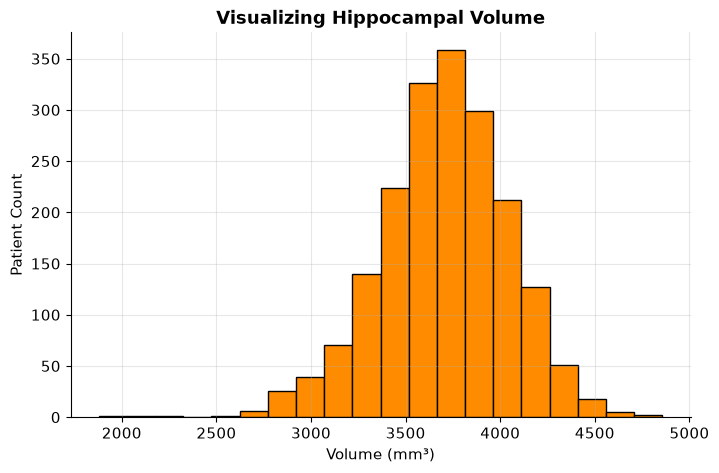

In [6]:
fig,ax = plt.subplots()
ax.hist(data["hippocampal_volume_mm3"],bins=20,
        color="darkorange", edgecolor="black")
ax.set_title("Visualizing Hippocampal Volume")
ax.set_xlabel("Volume (mm³)")
ax.set_ylabel("Patient Count")
plt.show()

Most values for hippocampal volume hover between 3500mm³ and 4000mm³. This is statistically supported given the corrected hippocampal volume average is 3702.857367593078.

________

**$bar chart$**

diagnosis
Normal (CN)      1218
MCI               745
Dementia (AD)     156
Name: count, dtype: int64


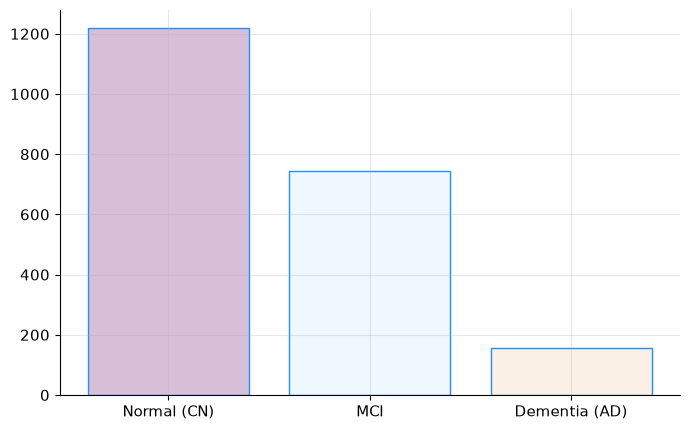

In [7]:
diagnosis = data['diagnosis'].unique()
counts = data["diagnosis"].value_counts().reindex(diagnosis)
print(counts)

colors = ['thistle', 'aliceblue', 'linen']
fig,ax = plt.subplots(figsize=(8,5),)
bars= ax.bar(counts.index, counts.values, 
             color=colors, edgecolor='dodgerblue')

We used this to compare against the count plot, but it gives a less detailed explanation, leaving the account plot as a better graph for quantitative bins. 

_________

**$count plot$**

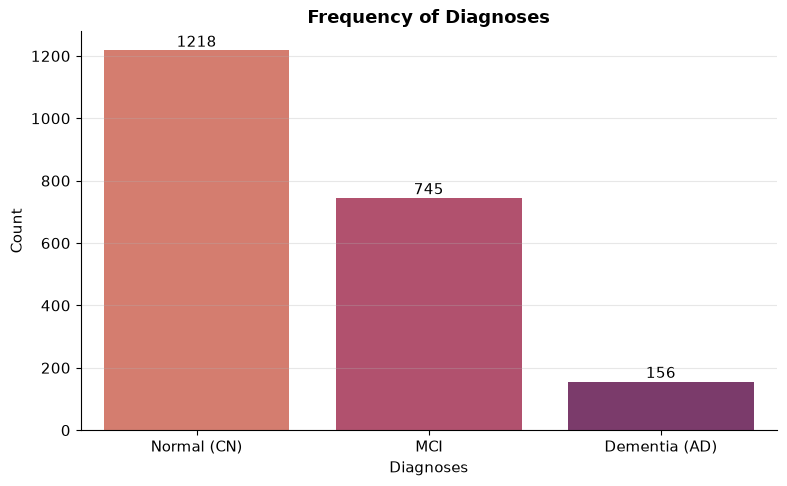

In [8]:
plt.figure(figsize=(8,5))
ax = sns.countplot(data=data, x='diagnosis', hue='diagnosis', 
                   palette='flare', legend=False, 
                   order=data['diagnosis'].value_counts().index,)
    
for container in ax.containers:
    ax.bar_label(container)

# flare
plt.title("Frequency of Diagnoses")
plt.xlabel("Diagnoses")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

With redundant naming reduced, we can see accurately how the diagnosis were spread across each patient with each bar indicating a sub population.

______

$II.$

Using `.groupby()` for comparative visualization.

______

$lineplot$

In [9]:
hippocampal_vol_avg = data.groupby(
    "diagnosis")["hippocampal_volume_mm3"].mean()

hippocampal_vol_avg.sort_values(
    ascending=False).reset_index()

,diagnosis,hippocampal_volume_mm3
0,Normal (CN),3834.001830
1,MCI,3592.451852
2,Dementia (AD),3207.769784


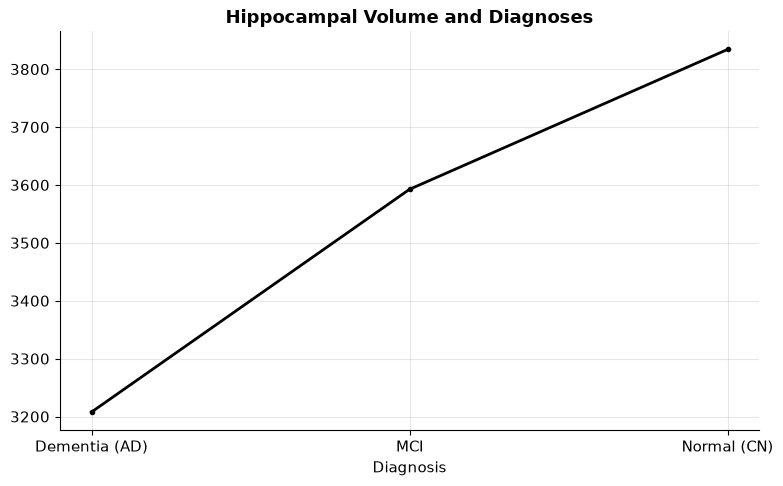

In [10]:
fig, ax = plt.subplots(figsize=(8, 5), sharey=False)
ax.plot(hippocampal_vol_avg.sort_values(ascending=True),
        color='black', marker='.', lw=2)

ax.set_title("Hippocampal Volume and Diagnoses")
ax.set_xlabel("Diagnosis")

plt.tight_layout()

As hippocampal volume increases, brain health seems to increase linearly. 

**A more interesting line plot maps the relationship between MoCA score and Hippocampal volume:**

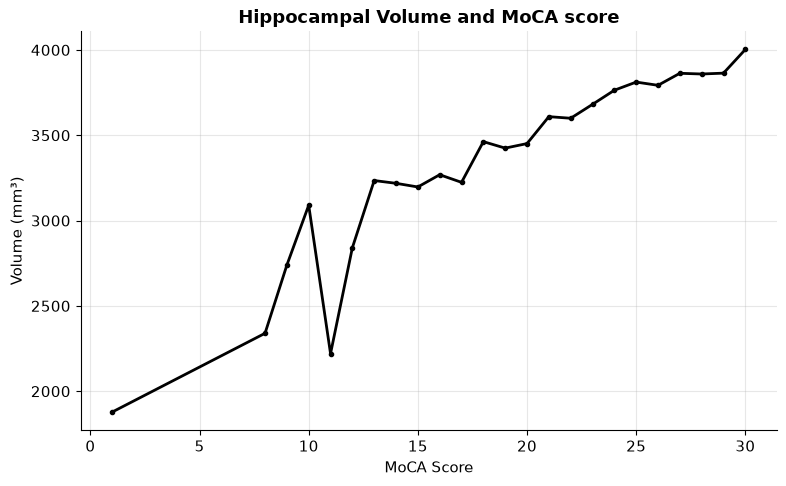

In [11]:
hippocampal_moca = data.groupby("moca")["hippocampal_volume_mm3"].mean()


fig, ax = plt.subplots(figsize=(8, 5), sharey=False)
ax.plot(hippocampal_moca, color='black', marker='.', lw=2)

ax.set_title("Hippocampal Volume and MoCA score")
ax.set_xlabel("MoCA Score")
ax.set_ylabel("Volume (mm³)")

plt.tight_layout()


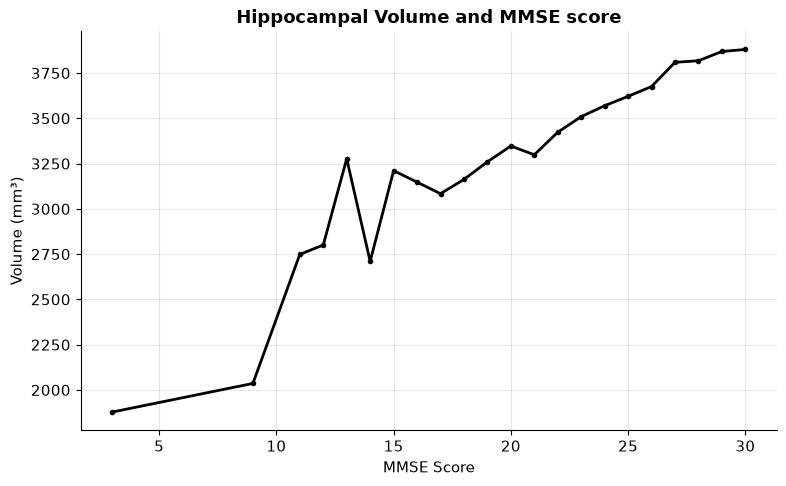

In [12]:
hippocampal_moca = data.groupby("mmse")["hippocampal_volume_mm3"].mean()


fig, ax = plt.subplots(figsize=(8, 5), sharey=False)
ax.plot(hippocampal_moca, color='black', marker='.', lw=2)

ax.set_title("Hippocampal Volume and MMSE score")
ax.set_xlabel("MMSE Score")
ax.set_ylabel("Volume (mm³)")

plt.tight_layout()


For both line plots, the scores begin to increse linearly with volume. On the bottom plot, however, the change in cognitive ability is better approximated at an MMSE score of 10, suggesting that the MMSE better judges Dementia diagnoses than the MoCA, which showed more variation and hence greater ambiguity.

_________

## section ii

_________

**$scatterplot$**

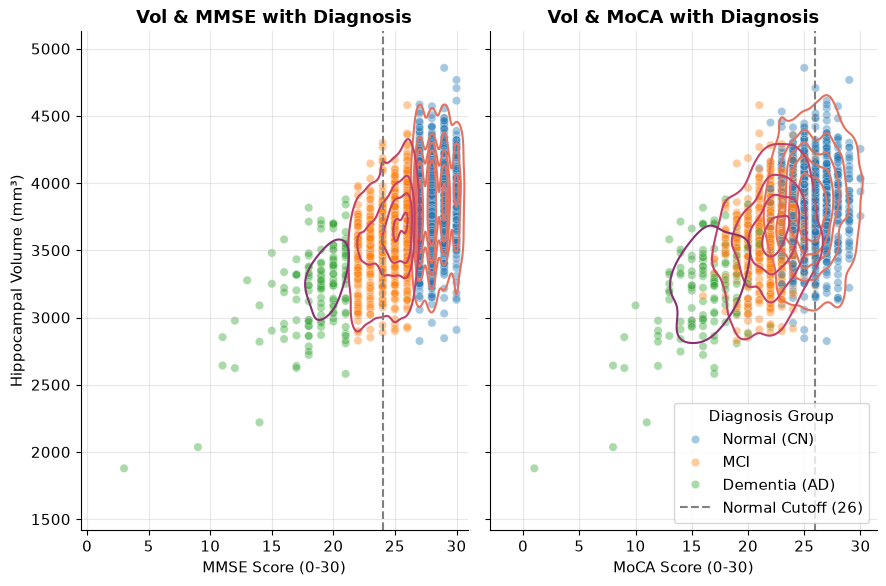

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(9, 6), sharey=True)

# left plots MMSE vs. Hippocampal Volume
sns.scatterplot(data=data, x='mmse', y='hippocampal_volume_mm3', hue='diagnosis',
                alpha=0.4, ax=axes[0], legend=False)
sns.kdeplot(data=data, x='mmse', y='hippocampal_volume_mm3', hue='diagnosis',
            levels=6, palette='flare', ax=axes[0], legend=False)
axes[0].axvline(24, color='gray', linestyle='--', label='Clinical Cutoff (24)')
axes[0].set_title('Vol & MMSE with Diagnosis')
axes[0].set_xlabel('MMSE Score (0-30)')
axes[0].set_ylabel('Hippocampal Volume (mm³)')
axes[0].grid(True, alpha=0.3)

# right plots MoCA vs. Hippocampal Volume
sns.scatterplot(data=data, x='moca', y='hippocampal_volume_mm3', hue='diagnosis',
                alpha=0.4, ax=axes[1])
sns.kdeplot(data=data, x='moca', y='hippocampal_volume_mm3', hue='diagnosis',
            palette='flare', levels=6, ax=axes[1], legend=False)
axes[1].axvline(26, color='gray', linestyle='--', label='Normal Cutoff (26)')
axes[1].set_title('Vol & MoCA with Diagnosis')
axes[1].set_xlabel('MoCA Score (0-30)')
axes[1].legend(title='Diagnosis Group', loc='lower right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("my_plot_clean.png", dpi=300, bbox_inches="tight")
plt.show()

This is my favorite visualization by far.

The cutoff lines indicate the scores necessary to diagnose patients with cognitive impairment.

The most important feature it reveals is the effectiveness of the cognitive test scores. MCI is important to identify because it plausibly could be a sign of early Dimentia. The problem make clear through this scatter plot is that MCI is often over the cutoff (Left), meaning that the MMSE does a poorer job at identifying need for care.

_________

$heatmap$ $of$ $correlations$

The final useful strategy is to one-hot enode Yes (1) or No (0) categorical variables. These are the presense of the gene APOE4 and Hypertension. This will be used to show the correlation between these biological risk factors and hippocampal volume.

In [14]:
data['apoe4_q'] = (data['apoe4_carrier'] == 'Yes').astype(int)
data['hypertension_q'] = (data['hypertension'] == 'Yes').astype(int)

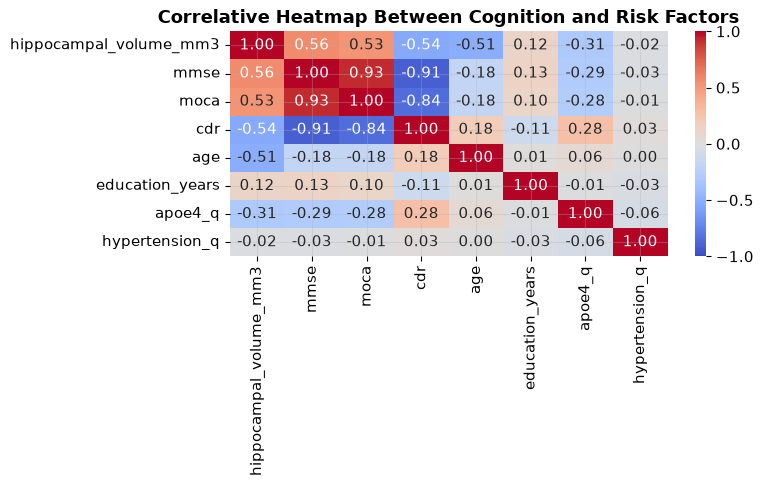

In [15]:
plt.figure(figsize=(8, 5))

corr_cols = [
    'hippocampal_volume_mm3', 'mmse', 'moca', 'cdr',
    'age', 'education_years', 'apoe4_q', 'hypertension_q'
]
corr_matrix = data[corr_cols].corr()

sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlative Heatmap Between Cognition and Risk Factors')
plt.tight_layout()
plt.savefig('section2_correlation_heatmap.png', dpi=300)
plt.show()


Our observation above is supported here. The MMSE does actually have a higher (positive or negative) correlation with hippocampal volume and the factors that determine health (i.e. education years: positive, cdr*: negative, APOE4: negative). One important nuance to the data is the inclusion of the Hypertension factor, which has barely any statistical correlation with anything--especially not age, which varied quite strongly with hippocampal volume (r= -0.51).


*cdr: Clinical Dimensia Rating. 

_____

$summary$

The data said overall had many interesting nuances to test: we had null variables such as Hypertension, important biological variables, such as the APOE4 gene age and hippocampal volume which were all used to develop answers regarding a patient cognitive impairment development. We learned that the MOCA test was less effective at the determining mild cognitive impairment successfully, along with the gene APOE4's negative affect on cognition. Our ability to evaluate the data based on their visual relationships was strong given the various dimensions that we could work with.

- Our main findings were with respect to the confirmation of a decrease in hippocampal volume across severity of diagnoses, along with the accuracy and sensitivity of congnitive tests. 

In [16]:
data.to_csv("cleaned_data.csv", index=False)